# CNN Architecture and Training

## Handwritten Digit Recognition Using MNIST

This notebook covers the preparation of the MNIST dataset, the development of a Convolutional Neural Network (CNN), and the training and optimisation process.

The objective is to develop a model capable of accurately classifying handwritten digits while evaluating its generalisation performance on unseen data.

In [1]:
import numpy as np

import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.datasets import mnist

## 1. Dataset Loading

The MNIST dataset consists of grayscale images of handwritten digits (0–9), each with a resolution of 28 × 28 pixels.

The dataset is loaded using Keras, which provides predefined training and test sets.

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


## 2. Initial Data Inspection

Inspect the dataset dimensions, pixel intensity ranges, and available classes to verify its structure before preprocessing.

In [3]:
# Training
print(np.min(x_train), np.max(x_train))
print(np.unique(y_train))

# Test
print(np.min(x_test), np.max(x_test))
print(np.unique(y_test))

0 255
[0 1 2 3 4 5 6 7 8 9]
0 255
[0 1 2 3 4 5 6 7 8 9]


## 3. Training and Validation Split

The original training dataset is divided into training and validation subsets using stratified sampling.

- **Training:** 50,000 images
- **Validation:** 10,000 images
- **Test:** 10,000 images (reserved for final evaluation)

A fixed random seed ensures reproducibility, while stratification preserves the approximate class distribution across the training and validation sets.

In [4]:
from sklearn.model_selection import train_test_split

# Raw MNIST images
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=10000, random_state=42, shuffle=True, stratify=y_train
)

In [5]:
print(x_train.shape)
print(x_val.shape)
print(x_test.shape)
print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

(50000, 28, 28)
(10000, 28, 28)
(10000, 28, 28)
(50000,)
(10000,)
(10000,)


## 5. Input Reshaping

An additional channel dimension is introduced to match the input format expected by the CNN.

The resulting image tensors follow the structure:

**(samples, height, width, channels)**

For MNIST, each image has a single grayscale channel.

In [6]:
images = [x_train, x_val, x_test]
normalized_images = []
for d in images:
    new_object = d.astype("float32")/255.0
    normalized_images.append(new_object)

# Normalized images (float32, values in [0, 1])
x_train_s, x_val_s, x_test_s = normalized_images

In [7]:
print(x_train_s.dtype)

print(x_train_s.min(), x_train_s.max())

print(x_val_s.min(), x_val_s.max())

print(x_test_s.min(), x_test_s.max())

float32
0.0 1.0
0.0 1.0
0.0 1.0


## 6. Preprocessing Verification

Verify that the training, validation, and test datasets have the expected dimensions, data types, and normalised pixel ranges before model development.

In [8]:
normalized_images = [x_train_s, x_val_s, x_test_s]
final_pre = []
for d in normalized_images:
    new_object = np.expand_dims(d,axis=-1)
    final_pre.append(new_object)

# CNN-ready images (N, 28, 28, 1)
x_train_f, x_val_f, x_test_f = final_pre

print(x_train_f.shape, x_val_f.shape, x_test_f.shape)

(50000, 28, 28, 1) (10000, 28, 28, 1) (10000, 28, 28, 1)


## 7. Computational Environment

Check the TensorFlow version and available computing devices before model training.

In [9]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


In [10]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential(
    [
        keras.Input(shape=(28,28,1)),
        layers.Conv2D(32,kernel_size=(3,3),padding="same",activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64,kernel_size=(3,3),padding="same",activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dense(128,activation="relu"),
        layers.Dense(10,activation="softmax")
        
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [12]:
history = model.fit(x_train_f,y_train, batch_size=32,epochs=5,validation_data=(x_val_f,y_val))

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 22ms/step - accuracy: 0.9575 - loss: 0.1393 - val_accuracy: 0.9808 - val_loss: 0.0594
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.9866 - loss: 0.0447 - val_accuracy: 0.9848 - val_loss: 0.0481
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.9912 - loss: 0.0287 - val_accuracy: 0.9845 - val_loss: 0.0485
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 31s 20ms/step - accuracy: 0.9928 - loss: 0.0223 - val_accuracy: 0.9866 - val_loss: 0.0451
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 18ms/step - accuracy: 0.9946 - loss: 0.0164 - val_accuracy: 0.9867 - val_loss: 0.0501


In [13]:
t_loss = history.history["loss"]

In [14]:
t_acc = history.history["accuracy"]

In [15]:
v_loss = history.history["val_loss"]

In [16]:
v_acc = history.history["val_accuracy"]

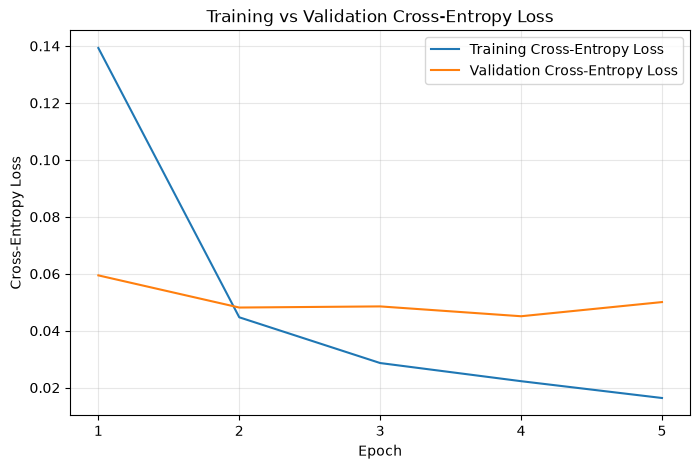

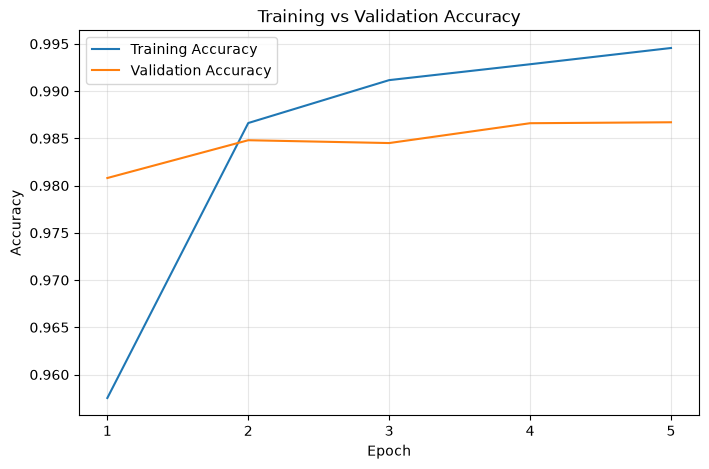

In [17]:
import matplotlib.pyplot as plt

def plot_training_history(train_values, val_values, metric_name):
    epochs = range(1, len(train_values) + 1)
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_values, label=f"Training {metric_name}")
    plt.plot(epochs, val_values, label=f"Validation {metric_name}")
    plt.title(f"Training vs Validation {metric_name}")
    plt.xlabel("Epoch")
    plt.ylabel(metric_name)
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    
plot_training_history(
    history.history["loss"],
    history.history["val_loss"],
    "Cross-Entropy Loss"
)

plot_training_history(
    history.history["accuracy"],
    history.history["val_accuracy"],
    "Accuracy"
)

In [18]:
model_dropout = keras.Sequential(
    [
        keras.Input(shape=(28,28,1)),
        layers.Conv2D(32,kernel_size=(3,3),padding="same",activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64,kernel_size=(3,3),padding="same",activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dense(128,activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10,activation="softmax")
        
    ]
)

model_dropout.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model_dropout.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [20]:
history_dropout = model_dropout.fit(x_train_f,y_train, batch_size=32,epochs=5,validation_data=(x_val_f,y_val))

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 37s 23ms/step - accuracy: 0.9466 - loss: 0.1723 - val_accuracy: 0.9800 - val_loss: 0.0600
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9813 - loss: 0.0602 - val_accuracy: 0.9873 - val_loss: 0.0446
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9875 - loss: 0.0418 - val_accuracy: 0.9859 - val_loss: 0.0527
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 18ms/step - accuracy: 0.9893 - loss: 0.0326 - val_accuracy: 0.9878 - val_loss: 0.0388
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9916 - loss: 0.0264 - val_accuracy: 0.9893 - val_loss: 0.0384


In [21]:
t_loss_d = history_dropout.history["loss"]
t_acc_d = history_dropout.history["accuracy"]
v_loss_d = history_dropout.history["val_loss"]
v_acc_d = history_dropout.history["val_accuracy"]

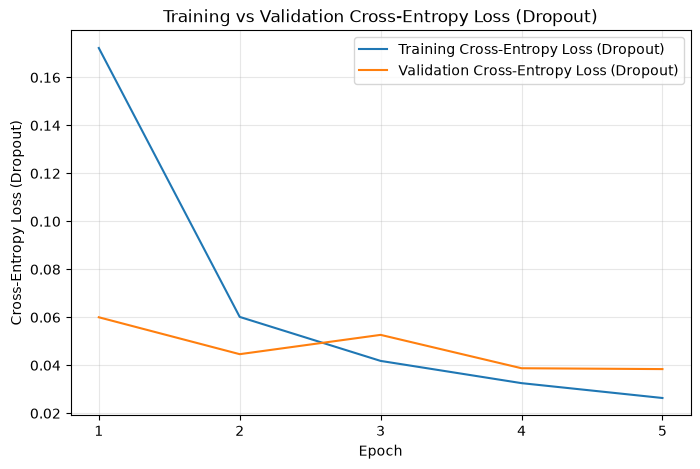

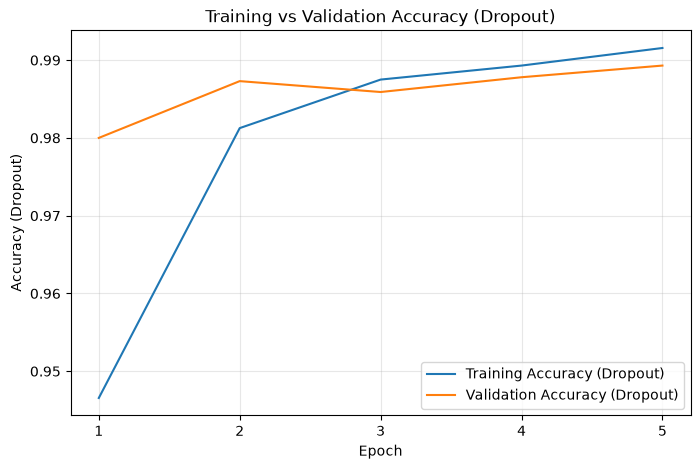

In [22]:
plot_training_history(
    history_dropout.history["loss"],
    history_dropout.history["val_loss"],
    "Cross-Entropy Loss (Dropout)"
)

plot_training_history(
    history_dropout.history["accuracy"],
    history_dropout.history["val_accuracy"],
    "Accuracy (Dropout)"
)

In [24]:
model.save("../results/models/cnn_baseline.keras")
model_dropout.save("../results/models/cnn_dropout.keras")